# Combined-Cycle Power Plant Output Prediction

This notebook trains and evaluates regression models to predict net electrical output (`PE`) from ambient and operating conditions. It keeps the test set separate from model selection, compares linear and tree-based approaches with cross-validation, and saves a compact fitted pipeline for the Flask app.

**Target:** `PE` (MW)  
**Features:** `AT`, `V`, `AP`, `RH`

In [32]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

from xgboost import XGBRegressor

## 1. Load and Inspect Data

The data path is resolved relative to the project, so the notebook does not depend on a particular Windows user or checkout location.

In [33]:
def find_project_root(start_dir=Path.cwd()):
    for candidate in (start_dir, *start_dir.parents):
        if (candidate / 'data' / 'cleaned_data.csv').is_file():
            return candidate
    raise FileNotFoundError('Could not find data/cleaned_data.csv from the current directory.')

PROJECT_ROOT = find_project_root()
DATA_PATH = PROJECT_ROOT / 'data' / 'cleaned_data.csv'
df = pd.read_csv(DATA_PATH)

print(f'Dataset: {DATA_PATH.relative_to(PROJECT_ROOT)}')
print(f'Shape: {df.shape[0]:,} rows x {df.shape[1]} columns')

Dataset: data\cleaned_data.csv
Shape: 9,527 rows x 5 columns


,AT,V,AP,RH,PE
0,14.96,41.76,1024.07,73.17,463.26
1,25.18,62.96,1020.04,59.08,444.37
2,5.11,39.40,1012.16,92.14,488.56
3,20.86,57.32,1010.24,76.64,446.48
4,10.82,37.50,1009.23,96.62,473.90


,missing_values
AT,0
V,0
AP,0
RH,0
PE,0


,count,mean,std,min,25%,50%,75%,max
AT,9527.0,19.658225,7.444397,1.81,13.530,20.35,25.710,37.11
V,9527.0,54.293421,12.686309,25.36,41.740,52.08,66.510,81.56
AP,9527.0,1013.237084,5.940526,992.89,1009.085,1012.92,1017.200,1033.30
RH,9527.0,73.334951,14.607513,25.56,63.375,75.00,84.850,100.16
PE,9527.0,454.335910,17.039080,420.26,439.750,451.52,468.365,495.76


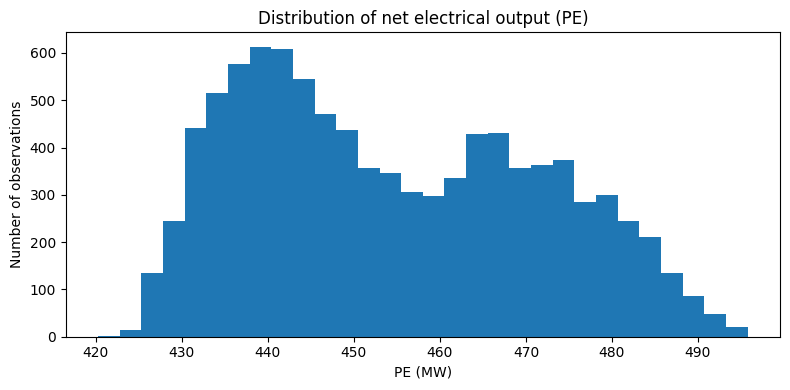

In [34]:
display(df.head())

missing_values = df.isna().sum().rename('missing_values')
display(missing_values.to_frame())
display(df.describe().T)

ax = df['PE'].plot(
    kind='hist',
    bins=30,
    title='Distribution of net electrical output (PE)',
    xlabel='PE (MW)',
    ylabel='Number of observations',
    figsize=(8, 4),
)
plt.tight_layout()
plt.show()

## 2. Define the Prediction Task

`PE` is the continuous target; the remaining columns are model inputs. A fixed 20% holdout is reserved for the final evaluation and is not used to select hyperparameters. The shuffled split estimates performance on unseen records; for forecasting future hours, replace it with a chronological split.

In [35]:
TARGET = 'PE'
FEATURE_COLUMNS = [column for column in df.columns if column != TARGET]

X = df[FEATURE_COLUMNS]
y = df[TARGET]

print(f'Target: {TARGET}')
print(f'Features ({len(FEATURE_COLUMNS)}): {FEATURE_COLUMNS}')

Target: PE
Features (4): ['AT', 'V', 'AP', 'RH']


In [36]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    shuffle=True,
)

print(f'Training rows: {len(X_train):,}')
print(f'Test rows: {len(X_test):,}')

Training rows: 7,621
Test rows: 1,906


## 3. Cross-Validated Model Selection

All preprocessing is inside the pipeline, so each transformation is fit only on a CV training fold. Scaling is applied to linear estimators; tree-based estimators use the raw features. Polynomial Ridge is included as a nonlinear feature-expansion baseline. The best settings are selected by five-fold CV RMSE.

In [37]:
model_pipeline = Pipeline(
    steps=[
        ('poly', 'passthrough'),
        ('scaler', 'passthrough'),
        ('regressor', LinearRegression()),
    ]
)

param_grid = [
    {
        'poly': ['passthrough'],
        'scaler': [StandardScaler()],
        'regressor': [LinearRegression()],
    },
    {
        'poly': ['passthrough'],
        'scaler': [StandardScaler()],
        'regressor': [Ridge()],
        'regressor__alpha': [0.1, 1.0, 10.0],
    },
    {
        'poly': ['passthrough'],
        'scaler': [StandardScaler()],
        'regressor': [Lasso()],
        'regressor__alpha': [0.01, 0.1, 1.0],
    },
    {
        'poly': ['passthrough'],
        'scaler': ['passthrough'],
        'regressor': [RandomForestRegressor(random_state=42)],
        'regressor__n_estimators': [50, 100],
        'regressor__max_depth': [5, 10, None],
    },
    {
        'poly': ['passthrough'],
        'scaler': ['passthrough'],
        'regressor': [XGBRegressor(random_state=42)],
        'regressor__n_estimators': [50, 100],
        'regressor__learning_rate': [0.01, 0.1],
        'regressor__max_depth': [3, 5],
    },
    {
        'poly': [PolynomialFeatures(include_bias=False)],
        'poly__degree': [2, 3],
        'scaler': [StandardScaler()],
        'regressor': [Ridge()],
        'regressor__alpha': [0.1, 1.0, 10.0],
    },
]

cv = KFold(n_splits=5, shuffle=True, random_state=42)

grid_search = GridSearchCV(
    estimator=model_pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring='neg_root_mean_squared_error',
    return_train_score=True,
    n_jobs=-1,
    verbose=1,
)

grid_search.fit(X_train, y_train)
best_model = grid_search.best_estimator_

print(f'Best CV RMSE: {-grid_search.best_score_:.4f}')
print(f'Best parameters: {grid_search.best_params_}')

Fitting 5 folds for each of 27 candidates, totalling 135 fits
Best CV RMSE: 3.4175
Best parameters: {'poly': 'passthrough', 'regressor': RandomForestRegressor(random_state=42), 'regressor__max_depth': None, 'regressor__n_estimators': 100, 'scaler': 'passthrough'}


### Compare the CV Results

The table below reports the best-scoring configuration for each estimator and feature transformation. Lower CV RMSE is better.

In [38]:
cv_results = pd.DataFrame(grid_search.cv_results_)
cv_results['model'] = cv_results['param_regressor'].apply(
    lambda estimator: type(estimator).__name__
 )

cv_results['feature_transform'] = cv_results['param_poly__degree'].apply(
    lambda degree: (
        f'Polynomial degree {int(degree)}'
        if pd.notna(degree)
        else 'Original features'
    )
)
cv_results['train_rmse'] = -cv_results['mean_train_score']
cv_results['cv_rmse'] = -cv_results['mean_test_score']
cv_results['cv_gap'] = cv_results['cv_rmse'] - cv_results['train_rmse']

best_by_model = (
    cv_results.sort_values('cv_rmse')
    .groupby(['model', 'feature_transform'], as_index=False)
    .first()
    [[
        'model',
        'feature_transform',
        'train_rmse',
        'cv_rmse',
        'cv_gap',
        'params',
    ]]
    .sort_values('cv_rmse')
    .reset_index(drop=True)
)

display(best_by_model.round({'train_rmse': 4, 'cv_rmse': 4, 'cv_gap': 4}))

,model,feature_transform,train_rmse,cv_rmse,cv_gap,params
0,RandomForestRegressor,Original features,1.2791,3.4175,2.1383,"{'poly': 'passthrough', 'regressor': RandomFor..."
1,XGBRegressor,Original features,2.9762,3.5396,0.5635,"{'poly': 'passthrough', 'regressor': XGBRegres..."
2,Ridge,Polynomial degree 3,4.1819,4.1955,0.0136,{'poly': PolynomialFeatures(include_bias=False...
3,Ridge,Polynomial degree 2,4.2473,4.2560,0.0087,{'poly': PolynomialFeatures(include_bias=False...
4,LinearRegression,Original features,4.5508,4.5524,0.0017,"{'poly': 'passthrough', 'regressor': LinearReg..."
5,Ridge,Original features,4.5508,4.5524,0.0017,"{'poly': 'passthrough', 'regressor': Ridge(), ..."
6,Lasso,Original features,4.5508,4.5525,0.0017,"{'poly': 'passthrough', 'regressor': Lasso(), ..."


## 4. Final Holdout Evaluation

After CV selects the model and settings, evaluate that fitted pipeline once on the reserved test set. These metrics estimate performance on unseen records and should not be used for further tuning.

In [39]:
test_predictions = best_model.predict(X_test)

holdout_metrics = pd.DataFrame(
    {
        'MAE': [mean_absolute_error(y_test, test_predictions)],
        'RMSE': [np.sqrt(mean_squared_error(y_test, test_predictions))],
        'R²': [r2_score(y_test, test_predictions)],
    },
    index=['Best CV model'],
)

display(holdout_metrics.round(4))

,MAE,RMSE,R²
Best CV model,2.4168,3.4484,0.9595


## 5. Model Size and Complexity Trade-Off

The full search may select a large, unrestricted forest. This second, smaller search constrains tree count, depth, and leaf size; compare its CV and holdout scores before using it as the deployable model.

In [40]:
from io import BytesIO

def serialized_size_mb(model, compress=0):
    buffer = BytesIO()
    joblib.dump(model, buffer, compress=compress)
    return buffer.tell() / (1024 ** 2)

compact_pipeline = Pipeline(
    steps=[
        ('poly', 'passthrough'),
        ('scaler', 'passthrough'),
        ('regressor', RandomForestRegressor(random_state=42)),
    ]
)

compact_search = GridSearchCV(
    estimator=compact_pipeline,
    param_grid={
        'regressor__n_estimators': [20, 50],
        'regressor__max_depth': [8, 12],
        'regressor__min_samples_leaf': [1, 2],
    },
    cv=cv,
    scoring='neg_root_mean_squared_error',
    return_train_score=True,
    n_jobs=-1,
    verbose=1,
)
compact_search.fit(X_train, y_train)
compact_model = compact_search.best_estimator_

compact_predictions = compact_model.predict(X_test)
best_predictions = best_model.predict(X_test)

model_comparison = pd.DataFrame(
    [
        {
            'model': 'Full CV winner',
            'cv_rmse': -grid_search.best_score_,
            'test_mae': mean_absolute_error(y_test, best_predictions),
            'test_rmse': np.sqrt(mean_squared_error(y_test, best_predictions)),
            'test_r2': r2_score(y_test, best_predictions),
            'size_mb': serialized_size_mb(best_model),
            'compressed_size_mb': serialized_size_mb(best_model, compress=3),
        },
        {
            'model': 'Compact Random Forest',
            'cv_rmse': -compact_search.best_score_,
            'test_mae': mean_absolute_error(y_test, compact_predictions),
            'test_rmse': np.sqrt(mean_squared_error(y_test, compact_predictions)),
            'test_r2': r2_score(y_test, compact_predictions),
            'size_mb': serialized_size_mb(compact_model),
            'compressed_size_mb': serialized_size_mb(compact_model, compress=3),
        },
    ]
)

print(f'Compact model parameters: {compact_search.best_params_}')
display(model_comparison.round(4))

Fitting 5 folds for each of 8 candidates, totalling 40 fits
Compact model parameters: {'regressor__max_depth': 12, 'regressor__min_samples_leaf': 2, 'regressor__n_estimators': 50}


,model,cv_rmse,test_mae,test_rmse,test_r2,size_mb,compressed_size_mb
0,Full CV winner,3.4175,2.4168,3.4484,0.9595,66.0372,14.3678
1,Compact Random Forest,3.5149,2.5503,3.5570,0.9569,7.5515,2.2539


## 6. Save the Deployment Pipeline

Save the compact pipeline, including its preprocessing and fitted estimator, to the project-level `model/` directory. This filename matches the Flask app configuration.

In [42]:
MODEL_DIR = PROJECT_ROOT / 'model'
MODEL_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = MODEL_DIR / 'best_model_compact.joblib'
joblib.dump(compact_model, MODEL_PATH, compress=3)
print(f'Saved deployment model: {MODEL_PATH.relative_to(PROJECT_ROOT)}')

reloaded_model = joblib.load(MODEL_PATH)
sample_prediction = reloaded_model.predict(X_test.iloc[[0]])[0]
print(f'Reload smoke test prediction: {sample_prediction:.2f} MW')

Saved deployment model: model\best_model_compact.joblib
Reload smoke test prediction: 464.53 MW
